# Exploratory Data Analysis



### 1. Import Libraries

In [28]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
print('Visualization libraries initialized.')

Visualization libraries initialized.


### 2. Load Cleaned Transactions

In [29]:
data_path = os.path.join('..', 'data', 'processed', 'cleaned_transactions.csv')
df = pd.read_csv(data_path)
df['timestamp'] = pd.to_datetime(df['timestamp'])
print(f'Total records loaded: {len(df):,} transactions')
df[['transaction_id', 'account_id', 'timestamp', 'channel', 'merchant_category', 'amount', 'is_fraud']].head(3)

Total records loaded: 126,000 transactions


,transaction_id,account_id,timestamp,channel,merchant_category,amount,is_fraud
0,FLR250216186265,FLR-ACC-100000,2025-02-16 14:55:35,Card Not Present,Travel,84233.00,0
1,FLR250423143305,FLR-ACC-100000,2025-04-23 13:35:40,Web Dashboard,Subscription/SaaS,9143.33,0
2,FLR250424154897,FLR-ACC-100000,2025-04-24 12:30:34,Mobile App,Groceries,20639.00,0


### 3. Measure Fraud Frequency Across Transactions
Checks how common fraud is in the dataset compared to normal, legitimate transactions.


Legitimate transactions (0): 122,648 (97.34%)
Fraudulent transactions (1): 3,352 (2.66%)


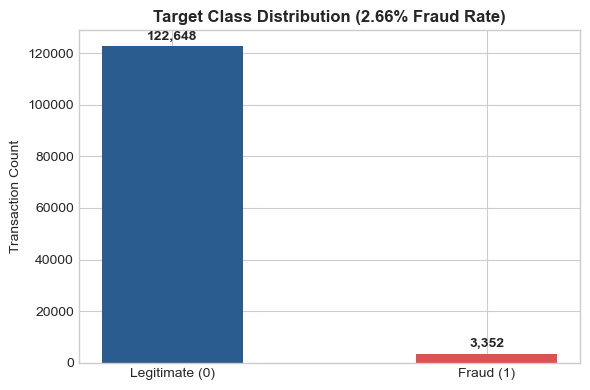

In [30]:
fraud_counts = df['is_fraud'].value_counts()
fraud_rate = df['is_fraud'].mean() * 100

print(f'Legitimate transactions (0): {fraud_counts[0]:,} ({100 - fraud_rate:.2f}%)')
print(f'Fraudulent transactions (1): {fraud_counts[1]:,} ({fraud_rate:.2f}%)')

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(['Legitimate (0)', 'Fraud (1)'], [fraud_counts[0], fraud_counts[1]], color=['#2b5c8f', '#d9534f'], width=0.45)
ax.set_title('Target Class Distribution (2.66% Fraud Rate)', fontsize=12, fontweight='bold')
ax.set_ylabel('Transaction Count')
for bar in bars:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, h + 1500, f'{h:,}', ha='center', va='bottom', fontweight='bold')
plt.tight_layout()
plt.show()

Class Imbalance Finding: Fraud is rare, making up only 2.66% of all transactions (3,352 fraud cases out of 126,000). If a system simply guessed that every payment was safe, it would look 97.34% accurate while missing every single fraud event. That is why simple accuracy is misleading here. Instead, model evaluation must focus on how many real frauds are caught (Recall) and how many alerts are actually real (Precision).


### 4. Analyze Spending Spikes and Purchase Sizes
Compares normal transactions against fraud to see if fraudsters spend much more than a customer's typical amount.


Relative Spend Ratio (amount_to_avg_ratio) Statistics
             count    mean     std   min   25%   50%    75%       max
is_fraud                                                             
0         122648.0    3.98   61.46  0.00  0.24  0.95   1.73  11044.22
1           3352.0  152.12  852.70  0.01  0.63  6.04  56.52  31762.69


C:\Users\earlc\AppData\Local\Temp\ipykernel_39636\3292495868.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='is_fraud', y='amount_to_avg_ratio', data=df, showfliers=False, palette=['#2b5c8f', '#d9534f'], ax=axes[0])
C:\Users\earlc\AppData\Local\Temp\ipykernel_39636\3292495868.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(['Legitimate', 'Fraud'])
C:\Users\earlc\AppData\Local\Temp\ipykernel_39636\3292495868.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='is_fraud', y='abs_amount', data=df, showfliers=False, palette=['#2b5c8f', '#d9534f'], ax=axes[1])
C:\Users\earlc

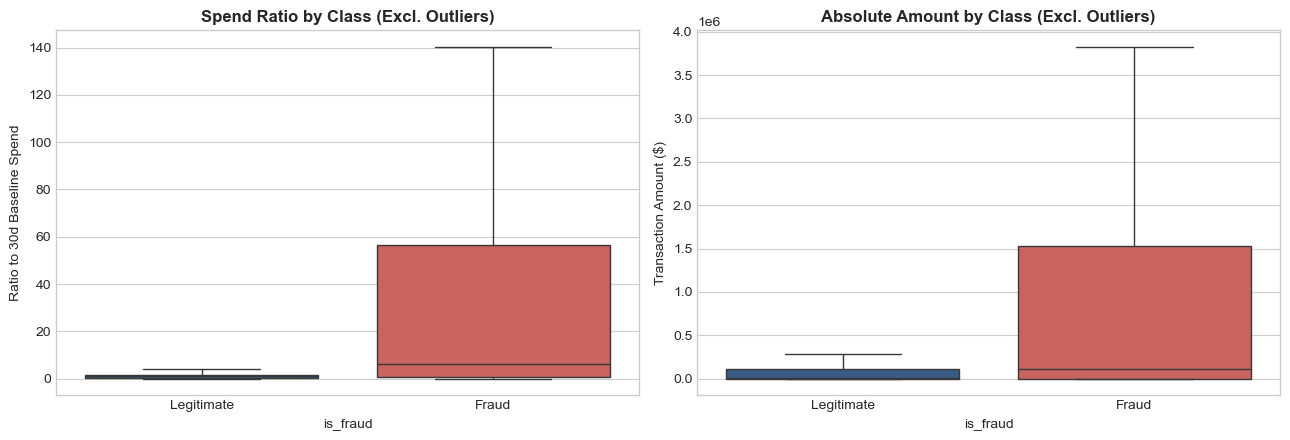

In [31]:
print('Relative Spend Ratio (amount_to_avg_ratio) Statistics')
print(df.groupby('is_fraud')['amount_to_avg_ratio'].describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(x='is_fraud', y='amount_to_avg_ratio', data=df, showfliers=False, palette=['#2b5c8f', '#d9534f'], ax=axes[0])
axes[0].set_title('Spend Ratio by Class (Excl. Outliers)', fontweight='bold')
axes[0].set_xticklabels(['Legitimate', 'Fraud'])
axes[0].set_ylabel('Ratio to 30d Baseline Spend')

sns.boxplot(x='is_fraud', y='abs_amount', data=df, showfliers=False, palette=['#2b5c8f', '#d9534f'], ax=axes[1])
axes[1].set_title('Absolute Amount by Class (Excl. Outliers)', fontweight='bold')
axes[1].set_xticklabels(['Legitimate', 'Fraud'])
axes[1].set_ylabel('Transaction Amount ($)')
plt.tight_layout()
plt.show()

Spend Divergence Finding: Fraudulent transactions are typically 6 times higher than a customer's normal 30-day spending average (with a median ratio of 6.04x), while normal payments stay right around their usual average (median of 0.95x). Unusually large spending spikes are one of the biggest clues that a transaction is fraud.


### 5. Review Risk by Payment Channel and Store Category
Checks which payment methods (like web, mobile app, bank wire) and store types have the highest rates of fraud.


Fraud Rate by Payment Channel
                  Volume  Fraud_Rate  Fraud_Rate_Pct
channel                                             
API/Integration    13083    0.036460            3.65
Web Dashboard      31330    0.029556            2.96
Mobile App         41615    0.025111            2.51
Card Not Present   17422    0.023419            2.34
Card Present       15080    0.022414            2.24
USSD                7470    0.021151            2.12

Fraud Rate by Top Merchant Categories
                   Volume  Fraud_Rate  Fraud_Rate_Pct
merchant_category                                    
Wire Transfer        7639    0.075795            7.58
Payroll Transfer    17117    0.055909            5.59
Crypto Exchange      1692    0.052009            5.20
Travel               7416    0.027913            2.79
P2P Transfer        10715    0.025385            2.54
Insurance            4528    0.023410            2.34
Electronics          6173    0.020735            2.07
Gambling/Gaming      

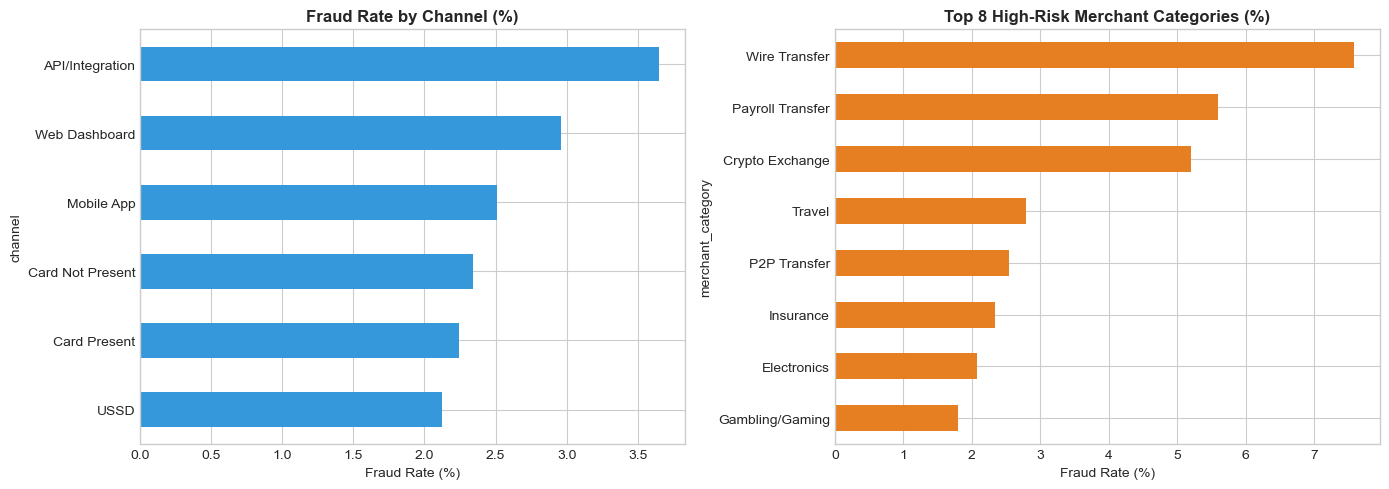

In [32]:
channel_summary = df.groupby('channel')['is_fraud'].agg(['count', 'mean']).rename(columns={'count': 'Volume', 'mean': 'Fraud_Rate'})
channel_summary['Fraud_Rate_Pct'] = (channel_summary['Fraud_Rate'] * 100).round(2)
print('Fraud Rate by Payment Channel')
print(channel_summary.sort_values(by='Fraud_Rate_Pct', ascending=False))

cat_summary = df.groupby('merchant_category')['is_fraud'].agg(['count', 'mean']).rename(columns={'count': 'Volume', 'mean': 'Fraud_Rate'})
cat_summary['Fraud_Rate_Pct'] = (cat_summary['Fraud_Rate'] * 100).round(2)
print('\nFraud Rate by Top Merchant Categories')
print(cat_summary.sort_values(by='Fraud_Rate_Pct', ascending=False).head(8))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
channel_summary['Fraud_Rate_Pct'].sort_values().plot(kind='barh', color='#3498db', ax=axes[0])
axes[0].set_title('Fraud Rate by Channel (%)', fontweight='bold')
axes[0].set_xlabel('Fraud Rate (%)')

cat_summary['Fraud_Rate_Pct'].sort_values().tail(8).plot(kind='barh', color='#e67e22', ax=axes[1])
axes[1].set_title('Top 8 High-Risk Merchant Categories (%)', fontweight='bold')
axes[1].set_xlabel('Fraud Rate (%)')
plt.tight_layout()
plt.show()

Category Finding: Bank wire transfers (7.58%), payroll transfers (5.59%), and crypto exchanges (5.20%) have the highest share of fraud. Among payment channels, automated system connections (APIs at 3.65%) and website logins (2.96%) carry the highest risk.


### 6. Compare Personal vs Business Accounts and Identity Tiers
Checks if fraud happens more often on personal accounts or business accounts, and whether customer identity verification levels (Basic, Verified, Enhanced) make a difference.


Fraud Risk by Account Type and KYC Tier
                             count      mean  Fraud_Rate_Pct
account_type kyc_tier                                       
Business     Tier1_Basic      7687  0.043450            4.34
             Tier2_Verified  22804  0.042975            4.30
             Tier3_Enhanced  13397  0.030828            3.08
Individual   Tier1_Basic     15125  0.026975            2.70
             Tier2_Verified  41290  0.018649            1.86
             Tier3_Enhanced  25697  0.017395            1.74


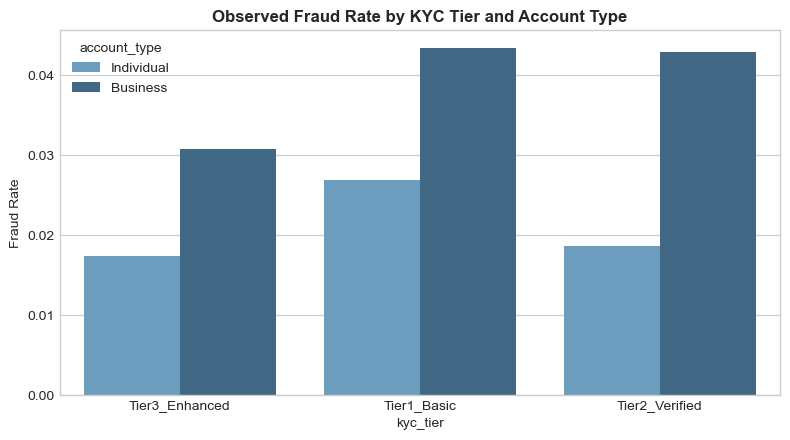

In [33]:
kyc_summary = df.groupby(['account_type', 'kyc_tier'])['is_fraud'].agg(['count', 'mean'])
kyc_summary['Fraud_Rate_Pct'] = (kyc_summary['mean'] * 100).round(2)
print('Fraud Risk by Account Type and KYC Tier')
print(kyc_summary)

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(x='kyc_tier', y='is_fraud', hue='account_type', data=df, errorbar=None, palette='Blues_d', ax=ax)
ax.set_title('Observed Fraud Rate by KYC Tier and Account Type', fontweight='bold')
ax.set_ylabel('Fraud Rate')
plt.tight_layout()
plt.show()

### 7. Inspect Unfamiliar Devices and Rapid Transaction Bursts
Checks if payments from new, unrecognized phones or computers and rapid bursts of transactions within an hour are riskier.


Device Novelty Risk
                count      mean  Fraud_Rate_Pct
is_new_device                                  
0              122105  0.025585            2.56
1                3895  0.058537            5.85

Velocity (Trailing 1-Hour Count) Statistics
             count  mean   std  min  25%  50%  75%  max
is_fraud                                               
0         122648.0   0.0  0.03  0.0  0.0  0.0  0.0  2.0
1           3352.0   0.4  0.52  0.0  0.0  0.0  1.0  3.0


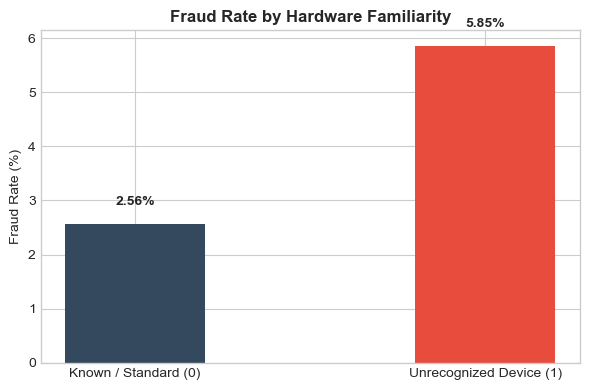

In [34]:
device_risk = df.groupby('is_new_device')['is_fraud'].agg(['count', 'mean'])
device_risk['Fraud_Rate_Pct'] = (device_risk['mean'] * 100).round(2)
print('Device Novelty Risk')
print(device_risk)

print('\nVelocity (Trailing 1-Hour Count) Statistics')
print(df.groupby('is_fraud')['transaction_velocity_1h'].describe().round(2))

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(['Known / Standard (0)', 'Unrecognized Device (1)'], device_risk['Fraud_Rate_Pct'], color=['#34495e', '#e74c3c'], width=0.4)
ax.set_title('Fraud Rate by Hardware Familiarity', fontweight='bold')
ax.set_ylabel('Fraud Rate (%)')
for bar in bars:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, h + 0.3, f'{h:.2f}%', ha='center', va='bottom', fontweight='bold')
plt.tight_layout()
plt.show()

Hardware Finding: When a transaction comes from a new, unrecognized phone or computer, the chance of fraud jumps to 5.85%, compared to just 2.56% on familiar devices.


### 8. Key Takeaways from Data Exploration
Four simple takeaways from the data exploration:

1. Big Spending Spikes: Transactions far above a customer's normal 30-day average (amount_to_avg_ratio) are the single strongest warning sign of fraud.
2. High-Risk Channels and Stores: Bank wires, crypto purchases, and automated connections require closer monitoring.
3. Unfamiliar Devices: Fraudsters frequently log in using a new phone or computer the customer has never used before.
4. Why Accuracy Lies: Because 97% of transactions are safe, a fraud model cannot just guess 'safe'. It needs to catch real criminals without producing an overwhelming number of false alarms.

---
Next Step: In 03_feature_engineering.ipynb, these discoveries are converted into clean numeric clues that machine learning models can understand.
